# Variant and Gene Annotation


- Which genes and transcript regions overlap or lie near historical targets and breed-specific candidates?
- Coordinate and allele checks, Ensembl and RefSeq annotations, coding predictions, and exact-ID MyGene joins annotate historical targets and LR/GSP candidates on ROS_Cfam_1.0.
- These methods describe genomic context and predicted coding consequences; a reusable inventory records coding and noncoding gene models.
- Overlap, proximity, and predicted consequences do not establish causal genes, regulatory targets, or biological effects.

### (Initialization) Import Directory-Free Helpers


In [1]:
def table_column_title(value):
    labels = {'canfam3.1': 'CanFam3.1', 'canfam4': 'CanFam4', 'ros_cfam_1.0': 'ROS_Cfam_1.0', 'gmmat': 'GMMAT', 'gemma': 'GEMMA', 'lr': 'LR', 'gsp': 'GSP', 'alt': 'ALT', 'ref': 'REF', 'snp': 'SNP', 'snps': 'SNPs', 'pca': 'PCA', 'umap': 'UMAP', 'plink': 'PLINK', 'ld': 'LD', 'qc': 'QC', 'id': 'ID', 'ids': 'IDs', 'rna': 'RNA', 'cds': 'CDS', 'utr': 'UTR', 'utrs': 'UTRs', 'dna': 'DNA', 'se': 'SE', 'reml': 'REML', 'ml': 'ML', 'i²': 'I²', 'r²': 'r²', 'χ²': 'χ²', 'ensembl': 'Ensembl', 'refseq': 'RefSeq', 'mygene.info': 'MyGene.Info'}
    import re
    return re.sub(r"[\w.²]+", lambda m: labels.get(m[0].lower(), m[0][0].upper() + m[0][1:]), value.replace("_", " "))

# Locate annotation outputs and define reusable readers and escaped HTML table displays.
# This keeps provider records readable while preserving their identifiers and source fields.

from pathlib import Path
import importlib
import sys
import csv
from collections import Counter, defaultdict
from html import escape
from IPython.display import display, HTML, Image

study_root = next(p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "scripts/notebook_support.py").exists())
sys.path.insert(0, str(study_root / "scripts"))
read_json = importlib.import_module("notebook_support").read_json
file_digest = importlib.import_module("notebook_support").file_digest
require_saved = importlib.import_module("notebook_review").require_saved
run_script = importlib.import_module("notebook_support").run_script
config = read_json(study_root / "config/annotation.json")
annotation_folder = study_root / config["output_directory"]

def read_table(path):
    with path.open(encoding="utf-8", newline="") as handle:
        return list(csv.DictReader(handle, delimiter="\t"))

def show_table(records, columns):
    header = "".join(f"<th style='text-align: center;'>{escape(table_column_title(c))}</th>" for c in columns)
    body = "".join("<tr>" + "".join(f"<td style='text-align: center;'>{escape(str(r.get(c, '')))}</td>" for c in columns) + "</tr>" for r in records)
    display(HTML(f"<table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>"))


### (Acquisition) Annotation Reference Resources
- Association inputs use CanFam4; historical coordinates use CanFam3.1.
- ROS conversion is only for annotation.
- Ensembl 116 and RefSeq 106 use sequence-identical ROS autosomes but retain separate gene models.
- Recent releases do not necessarily mean newly built genes.
- *download_annotation_assets.py*

In [2]:
# Download or verify the pinned annotation resources using the tested WSL/Linux environment.
# The completed resource receipt is required before interpreting candidate annotations.

# Run with the tested WSL/Linux project kernel. Completed caches are verified.
# run_script(study_root, "download_annotation_assets.py", linux=True)
resources = read_json(study_root / config["resource_directory"] / "assets.json")
assert resources["status"] == "complete"

### (Validation) Coordinate and Allele Checks
- Accepted LiftOver mappings must be unique, return exactly, match flanking sequence and have compatible alleles.
- Both available source representations must agree.
- Forty-one of 42 records pass.
- GSP `chr19_28283601` has three flanking mismatches and receives no gene/transcript annotation.
- All 12 retained historical targets agree between conversion routes.
- *annotate_candidates.py*
- *verify_annotation.py*

In [3]:
# Generate or verify the candidate coordinate crosswalk and independently check annotation outputs.
# Display failed mappings explicitly so unsupported coordinates do not silently receive gene annotations.

# run_script(study_root, "annotate_candidates.py", linux=True)
# run_script(study_root, "verify_annotation.py", linux=True)
summary = read_json(annotation_folder / "summary.private.json")
verification = read_json(annotation_folder / "verification.private.json")
assert verification["status"] == "passed"
variants = read_table(annotation_folder / "variant_crosswalk.private.tsv")
show_table([{"mapping status": key, "records": count}
            for key, count in summary["mapping_status"].items()], ["mapping status", "records"])
show_table([r for r in variants if r["mapping_status"] != "validated_coordinate"],
           ["record_id", "mapping_status", "context_bases", "context_mismatches", "reverse_status"])

Mapping Status,Records
validated_coordinate,41
sequence_context_failed,1


Record ID,Mapping Status,Context Bases,Context Mismatches,Reverse Status
GSP:chr19_28283601,sequence_context_failed,50,3,unique_exact_return


### (Annotation) Coding and Noncoding Overlap
- Tables distinguish overlap from nearby genes and keep both providers.
- Neighborhoods include genes within 500 kb plus the three nearest nonoverlapping genes, including ties.
- They are not LD blocks or proven regulatory targets.
- *plot_annotation_summary.py*

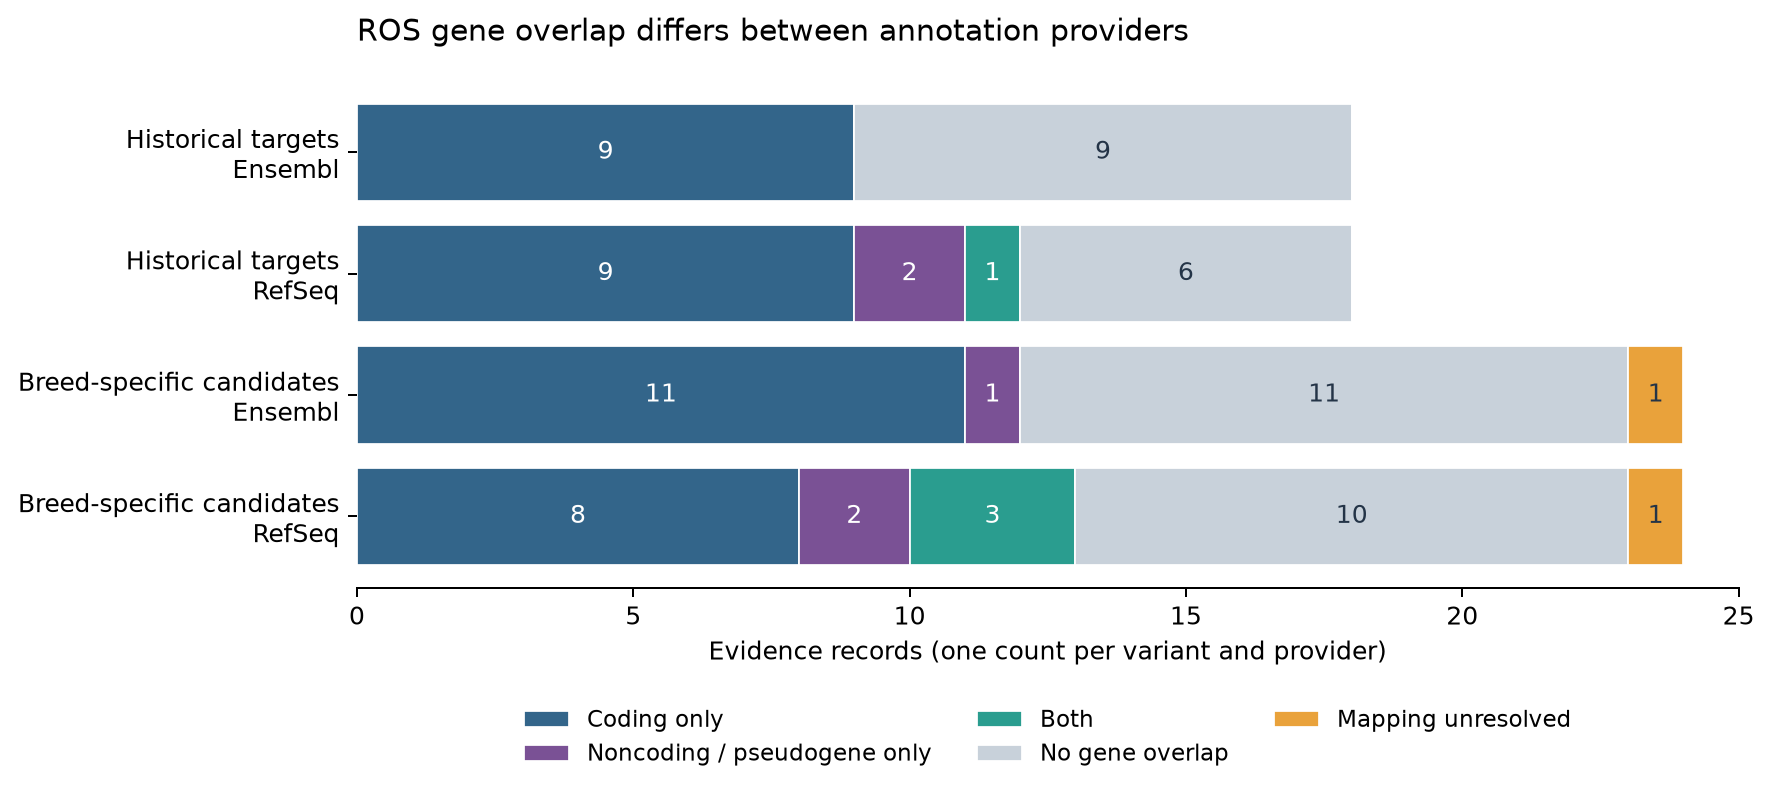

Record ID,Provider,Symbol,Gene ID,Biotype
historical:chr3.47103534,Ensembl,CHD2,ENSCAFG00845002446,protein_coding
historical:chr3.47134935,Ensembl,CHD2,ENSCAFG00845002446,protein_coding
historical:chr3.47212502,Ensembl,CHD2,ENSCAFG00845002446,protein_coding
historical:chr4.31420247,Ensembl,NRG3,ENSCAFG00845015872,protein_coding
historical:chr7.66358701,Ensembl,ABHD3,ENSCAFG00845015891,protein_coding
historical:chr11.38609196,Ensembl,ADAMTSL1,ENSCAFG00845013926,protein_coding
historical:chr13.58498102,Ensembl,,ENSCAFG00845008764,protein_coding
historical:chr13.59902870,Ensembl,AMBN,ENSCAFG00845010749,protein_coding
historical:chr36.25252101,Ensembl,PPP1R1C,ENSCAFG00845015312,protein_coding
historical:chr36.25252101,Ensembl,PDE1A,ENSCAFG00845015431,protein_coding


In [4]:
# Display provider-specific gene-overlap summaries and load the gene and transcript annotation tables.
# All overlapping records remain visible, including noncoding genes and provider differences.

# run_script(study_root, "plot_annotation_summary.py")
display(Image(filename=str(annotation_folder / "gene_overlap_summary.png")))
genes = read_table(annotation_folder / "gene_annotations.private.tsv")
transcripts = read_table(annotation_folder / "transcript_annotations.private.tsv")
overlap = [r for r in genes if r["relation"] == "overlap"]
show_table(overlap, ["record_id", "provider", "symbol", "gene_id", "biotype"])


### (Annotation) Transcript and Coding Predictions
- Annotations distinguish CDS, UTR, noncoding exon and intron overlap, without inferring enhancer, RNA or splice effects.
- GSP `chr27_8388210` predicts SCAF11 GCA → ACA (alanine → threonine) in both providers.
- Nine transcript codons are independently confirmed; residue positions vary.
- This is one variant, not nine signals or proven pathogenicity.
- *annotate_coding_consequences.py*
- *verify_coding_predictions.py*

In [5]:
# Predict coding consequences and check them independently against provider CDS sequences.
# Display transcript-specific predictions and interval categories without treating them as proven functional effects.

# run_script(study_root, "annotate_coding_consequences.py", linux=True)
# run_script(study_root, "verify_coding_predictions.py", linux=True)
coding = read_table(annotation_folder / "coding/coding_consequences.private.tsv")
show_table(coding, ["record_id", "provider", "transcript_id", "amino_acid_position",
                   "reference_codon", "alternate_codon", "reference_amino_acid", "alternate_amino_acid", "consequence"])
show_table([{"interval annotation": label, "transcript links": count}
            for label, count in Counter(r["region_annotation"] for r in transcripts).items()],
           ["interval annotation", "transcript links"])

Record ID,Provider,Transcript ID,Amino Acid Position,Reference Codon,Alternate Codon,Reference Amino Acid,Alternate Amino Acid,Consequence
GSP:chr27_8388210,Ensembl,ENSCAFT00845049162,598,GCA,ACA,A,T,missense_variant
GSP:chr27_8388210,Ensembl,ENSCAFT00845049274,598,GCA,ACA,A,T,missense_variant
GSP:chr27_8388210,RefSeq,rna-XM_038438414.1,598,GCA,ACA,A,T,missense_variant
GSP:chr27_8388210,RefSeq,rna-XM_038438410.1,598,GCA,ACA,A,T,missense_variant
GSP:chr27_8388210,RefSeq,rna-XM_038438413.1,598,GCA,ACA,A,T,missense_variant
GSP:chr27_8388210,RefSeq,rna-XM_038438411.1,598,GCA,ACA,A,T,missense_variant
GSP:chr27_8388210,RefSeq,rna-XM_038438412.1,598,GCA,ACA,A,T,missense_variant
GSP:chr27_8388210,RefSeq,rna-XM_038438416.1,468,GCA,ACA,A,T,missense_variant
GSP:chr27_8388210,RefSeq,rna-XM_038438415.1,468,GCA,ACA,A,T,missense_variant


Interval Annotation,Transcript Links
UTR_overlap,35
intron_overlap,134
noncoding_transcript_exon,3
CDS_overlap,9


### (Annotation) Existing Functional Information
- The optional MyGene supplement joins exact Entrez/Ensembl IDs.
- Of 1,120 provider records, 511 match uniquely, 607 are unmatched and two are ambiguous.
- MyGene covers coding genes here.
- Unmatched records remain visible; broader biological interpretation is pending.
- *enrich_annotation_context.py*

In [6]:
# Optionally rebuild the exact-ID MyGene supplement, or verify and summarize an existing supplement.
# Unmatched and ambiguous records remain explicit rather than being joined by gene name or uncertain coordinates.

# Optional regeneration requires pyarrow and an authorized source snapshot.
# Set a Linux-accessible path here to build the supplement in a fresh annotation run.
MYGENE_PARQUET = None
# if MYGENE_PARQUET is not None:
#     run_script(study_root, "enrich_annotation_context.py", "--mygene", MYGENE_PARQUET)
mygene_folder = annotation_folder / "mygene"
if (mygene_folder / "receipt.private.json").exists():
    supplement_receipt = read_json(mygene_folder / "receipt.private.json")
    assert supplement_receipt["sources"]["gene_links_sha256"] == file_digest(annotation_folder / "gene_annotations.private.tsv")
    for name, digest in supplement_receipt["outputs"].items():
        assert file_digest(mygene_folder / name) == digest
    context_summary = read_json(mygene_folder / "summary.private.json")
    show_table([{"match status": label, "provider gene records": context_summary[key]}
                for label, key in [("Exact unique ID", "exact_matches"), ("Unmatched", "unmatched"), ("Ambiguous", "ambiguous")]],
               ["match status", "provider gene records"])
else:
    print("Optional MyGene supplement is not present; provider annotations remain available.")


Match Status,Provider Gene Records
Exact unique ID,511
Unmatched,607
Ambiguous,2


### Interpretation
- Checked ROS positions, provider genes and transcript predictions aid interpretation without identifying causal genes or directional replication.
- [Annotation methods](../docs/methods/10%20Variant%20and%20gene%20annotation.md) document sources and checks.

### (Resource Construction) Complete Gene Inventory
- The resource contains 31,121 Ensembl and 42,272 RefSeq gene records: coding/noncoding genes, pseudogenes and immune segments.
- These are separate provider counts.
- SQLite preserves RNA/exon/CDS/UTR relationships; optional Parquet exports support reuse.
- The inventory retains 498 nested RNA parents and all supplied sequence categories.
- Coverage does not imply known function.
- *build_gene_inventory.py*
- *verify_gene_inventory.py*

In [7]:
# Build or verify the full coding/noncoding gene inventory and display its provider-specific classes.
# This preserves the gene universe independently of candidate selection and reports existing Parquet exports when present.

# run_script(study_root, "build_gene_inventory.py", linux=True)
# run_script(study_root, "verify_gene_inventory.py", linux=True)
inventory_folder = study_root / read_json(study_root / "config/gene_inventory.json")["output_directory"]
inventory = read_json(inventory_folder / "summary.private.json")
show_table(inventory["gene_classes"], ["provider", "gene_class", "count"])
print("Source RNA models:", inventory["transcript_counts"])
print("Nested RNA-parent records:", inventory["nested_RNA_parent_records"])
# Parquet export is optional and requires pyarrow in the export environment.
parquet_summary = inventory_folder / "parquet/summary.private.json"
if parquet_summary.exists():
    print("Verified typed Parquet rows:", read_json(parquet_summary)["rows"])

Provider,Gene Class,Count
Ensembl,immune_gene_segment,67
Ensembl,noncoding,9944
Ensembl,protein_coding,20500
Ensembl,pseudogene,610
RefSeq,immune_gene_segment,226
RefSeq,noncoding,15885
RefSeq,protein_coding,20950
RefSeq,pseudogene,5211


Source RNA models: {'Ensembl': 55335, 'RefSeq': 100602}
Nested RNA-parent records: 498
Verified typed Parquet rows: {'genes': 73393, 'transcripts': 155937}
